In [1]:
#importation de tout les package necessaire
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.naive_bayes import GaussianNB
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score, classification_report,
                             roc_auc_score, roc_curve)

## Partie A : Préparation

In [3]:
breast = load_breast_cancer()
X, y = breast.data, breast.target      # 0 = maligne, 1 = bénigne
print("X :", X.shape, " y :", y.shape)

X : (569, 30)  y : (569,)


**Q2.** Effectifs par classe

In [4]:
effectifs = np.bincount(y)
print("Maligne (0) :", effectifs[0], " Bénigne (1) :", effectifs[1])
print("Classe majoritaire :", round(effectifs.max() / len(y), 3))

Maligne (0) : 212  Bénigne (1) : 357
Classe majoritaire : 0.627


**Q3.** Séparation 80 % / 20 %

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print("Train :", X_train.shape, " Test :", X_test.shape)

Train : (455, 30)  Test : (114, 30)


**Q4.** Normalisation

In [8]:
#standardisation et normalisation de mes data
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)   # fit sur le train uniquement
X_test_sc = scaler.transform(X_test)

## Partie B : Cinq modèles

**Q5 et Q6.** Dictionnaire de modèles, entraînement, prédictions et probabilités

In [9]:
modeles = {
    'logistique': LogisticRegression(max_iter=1000),
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'SVM': SVC(kernel='rbf', probability=True, random_state=42),
    'Arbre de décision': DecisionTreeClassifier(max_depth=4, random_state=42),
    'Naive': GaussianNB(),
}

predictions, probabilites = {}, {}
for nom, modele in modeles.items():
    modele.fit(X_train_sc, y_train)
    predictions[nom] = modele.predict(X_test_sc)
    probabilites[nom] = modele.predict_proba(X_test_sc)[:, 1]

C:\Users\user\PycharmProjects\Tps_AI\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


## Partie C : Matrice de confusion et métriques

**Q7.** Matrice de confusion du SVM

In [10]:
y_pred_svm = predictions['SVM']
cm = confusion_matrix(y_test, y_pred_svm)
print(cm)
tn, fp, fn, tp = cm.ravel()
print("TN =", tn, " FP =", fp, " FN =", fn, " TP =", tp)

[[41  1]
 [ 1 71]]
TN = 41  FP = 1  FN = 1  TP = 71


Classe 1 (bénigne) = positive. Un **fn** est donc une tumeur **maligne classée bénigne** : erreur grave.

**Q8.** Métriques à la main, puis vérification

In [11]:
accuracy = (tp + tn) / (tp + tn + fp + fn)
precision = tp / (tp + fp)
rappel = tp / (tp + fn)
f1 = 2 * precision * rappel / (precision + rappel)
print("À la main    :", round(accuracy, 4), round(precision, 4), round(rappel, 4), round(f1, 4))

print("Avec sklearn :", round(accuracy_score(y_test, y_pred_svm), 4),
      round(precision_score(y_test, y_pred_svm), 4),
      round(recall_score(y_test, y_pred_svm), 4),
      round(f1_score(y_test, y_pred_svm), 4))

À la main    : 0.9825 0.9861 0.9861 0.9861
Avec sklearn : 0.9825 0.9861 0.9861 0.9861


**Q9.** Classe maligne positive (`pos_label=0`)

In [12]:
print("Précision :", round(precision_score(y_test, y_pred_svm, pos_label=0), 4))
print("Rappel    :", round(recall_score(y_test, y_pred_svm, pos_label=0), 4))
print("F1        :", round(f1_score(y_test, y_pred_svm, pos_label=0), 4))

Précision : 0.9762
Rappel    : 0.9762
F1        : 0.9762


**Q10.** `classification_report`

In [13]:
print(classification_report(y_test, y_pred_svm, target_names=breast.target_names))

              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



La ligne *benign* correspond à la Q8 et la ligne *malignant* à la Q9.

**Q11.** Comparaison des cinq modèles

In [14]:
lignes = []
for nom in modeles:
    p = predictions[nom]
    lignes.append({
        'Modèle': nom,
        'Accuracy': accuracy_score(y_test, p),
        'Précision (maligne)': precision_score(y_test, p, pos_label=0),
        'Rappel (maligne)': recall_score(y_test, p, pos_label=0),
        'F1 (maligne)': f1_score(y_test, p, pos_label=0),
        'ROC-AUC': roc_auc_score(y_test, probabilites[nom]),
    })
pd.DataFrame(lignes).set_index('Modèle').round(4)

,Accuracy,Précision (maligne),Rappel (maligne),F1 (maligne),ROC-AUC
Modèle,,,,,
logistique,0.9825,0.9762,0.9762,0.9762,0.9954
KNN,0.9561,0.9512,0.9286,0.9398,0.9788
SVM,0.9825,0.9762,0.9762,0.9762,0.9950
Arbre de décision,0.9386,0.9070,0.9286,0.9176,0.9342
Naive,0.9298,0.9048,0.9048,0.9048,0.9868


**Q12.** Courbes ROC

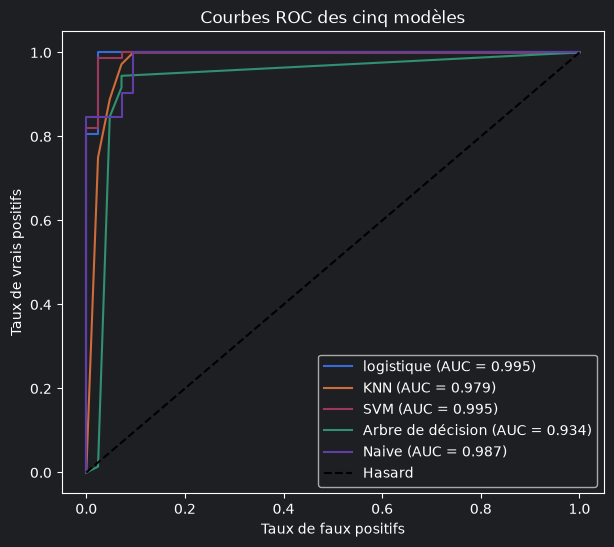

In [15]:
plt.figure(figsize=(7, 6))
for nom in modeles:
    fpr, tpr, _ = roc_curve(y_test, probabilites[nom])
    plt.plot(fpr, tpr, label=f"{nom} (AUC = {roc_auc_score(y_test, probabilites[nom]):.3f})")
plt.plot([0, 1], [0, 1], 'k--', label="Hasard")
plt.title("Courbes ROC des cinq modèles")
plt.xlabel("Taux de faux positifs")
plt.ylabel("Taux de vrais positifs")
plt.legend(loc='lower right')
plt.show()

**Q13.** Modèle retenu

La **régression logistique** ou la **SVM** : rappel maligne le plus élevé  0,976, avec le SVM, meilleur AUC et modèle simple à expliquer.

## Partie D : Arbre de décision et surapprentissage

**Q14.** Arbre sur les données non normalisées

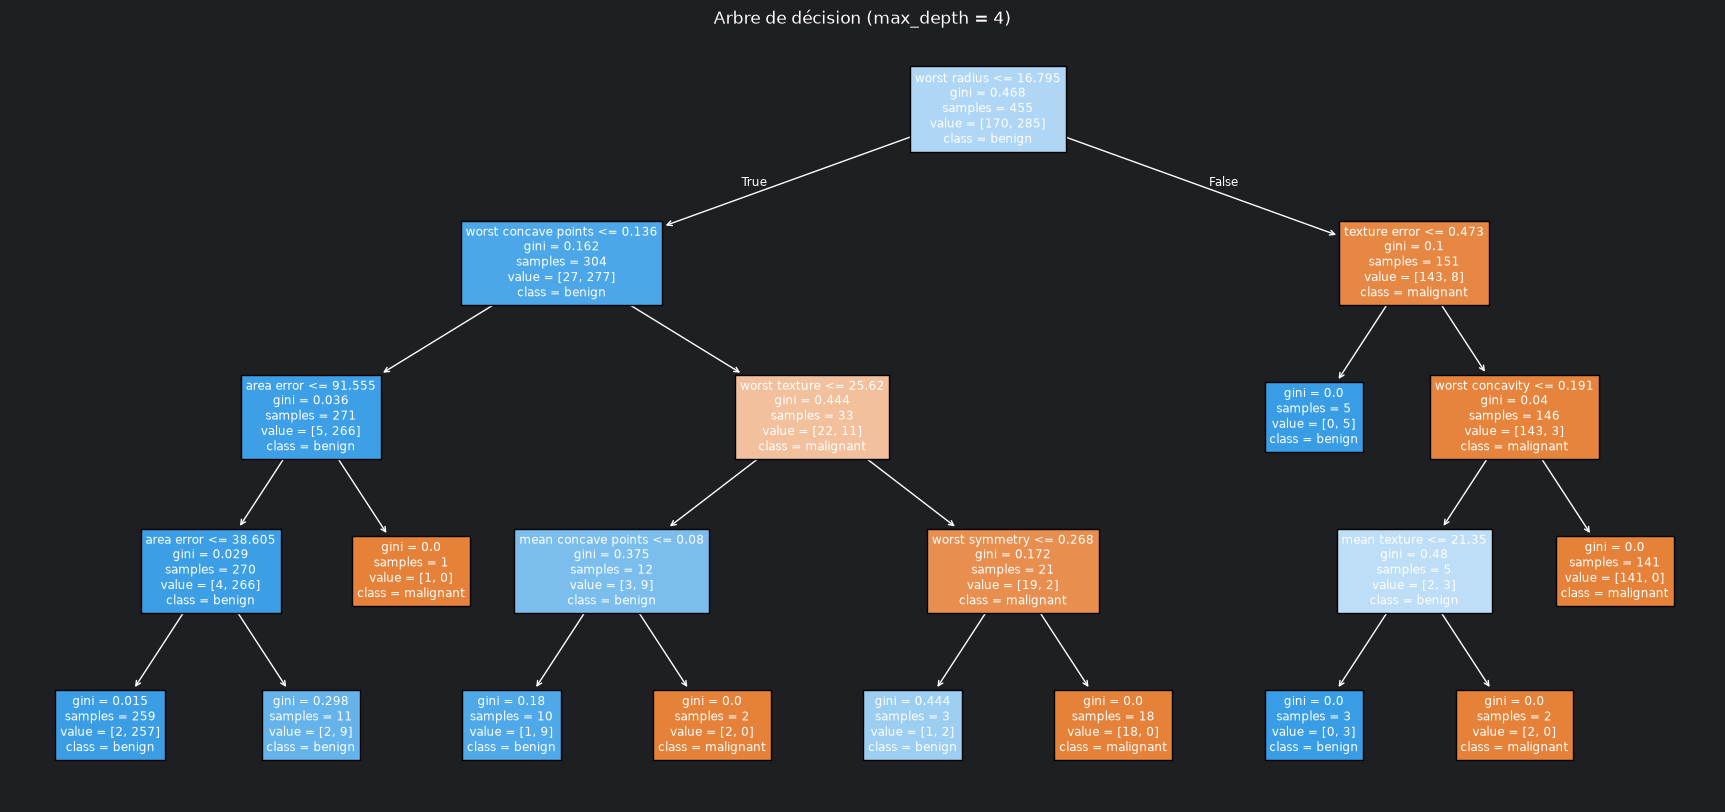

Variable à la racine : worst radius


In [16]:
arbre = DecisionTreeClassifier(max_depth=4, random_state=42).fit(X_train, y_train)

plt.figure(figsize=(22, 10))
plot_tree(arbre, feature_names=breast.feature_names,
          class_names=breast.target_names, filled=True)
plt.title("Arbre de décision (max_depth = 4)")
plt.show()

print("Variable à la racine :", breast.feature_names[arbre.tree_.feature[0]])

**Q15.** Cinq variables les plus importantes

In [17]:
importances = pd.Series(arbre.feature_importances_, index=breast.feature_names)
print(importances.sort_values(ascending=False).head(5).round(3))

worst radius            0.734
worst concave points    0.122
texture error           0.046
worst texture           0.032
worst concavity         0.017
dtype: float64


**Q16.** Accuracy selon `max_depth`

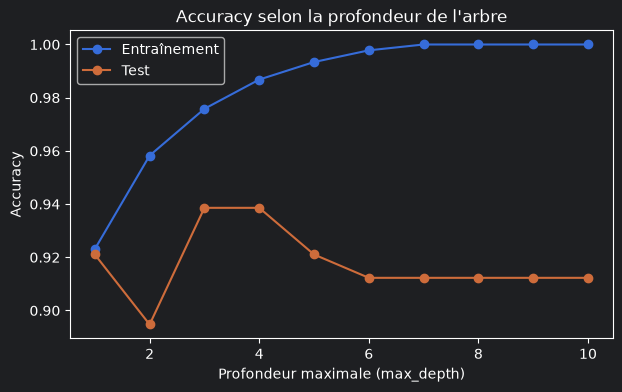

In [18]:
profondeurs = range(1, 11)
acc_train, acc_test = [], []
for d in profondeurs:
    a = DecisionTreeClassifier(max_depth=d, random_state=42).fit(X_train, y_train)
    acc_train.append(a.score(X_train, y_train))
    acc_test.append(a.score(X_test, y_test))

plt.figure(figsize=(7, 4))
plt.plot(profondeurs, acc_train, marker='o', label="Entraînement")
plt.plot(profondeurs, acc_test, marker='o', label="Test")
plt.title("Accuracy selon la profondeur de l'arbre")
plt.xlabel("Profondeur maximale (max_depth)")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

## Partie E : Le piège de l'accuracy

**Q17.** `DummyClassifier`

In [19]:
dummy = DummyClassifier(strategy='most_frequent').fit(X_train_sc, y_train)
y_pred_dummy = dummy.predict(X_test_sc)

print("Accuracy :", round(accuracy_score(y_test, y_pred_dummy), 3))
print("Rappel (maligne) :", recall_score(y_test, y_pred_dummy, pos_label=0, zero_division=0))

Accuracy : 0.632
Rappel (maligne) : 0.0
